
Start time:  2025-04-21 16:25:42.441347




Creating network of 2 cell populations on 1 hosts...: 100%|##########|


  Number of cells on node 0: 40 
  Done; cell creation time = 0.01 s.
Making connections...


  S->I: 100%|##########| Creating synaptic connections for 20/20 presynaptic cells on node 0 (divergent connectivity)
  I->S: 100%|##########| Creating synaptic connections for 20/20 postsynaptic cells on node 0 (probabilistic connectivity)

  Number of connections on node 0: 299 
  Done; cell connection time = 0.03 s.
Adding stims...
  Number of stims on node 0: 20 
  Done; cell stims creation time = 0.00 s.
Recording 1 traces of 1 types on node 0

Running simulation using NEURON for 1000.0 ms...


  Done; run time = 0.48 s; real-time ratio: 2.08.

Gathering data...
  Done; gather time = 0.01 s.

Analyzing...
  Cells: 40
  Connections: 319 (7.97 per cell)
  Spikes: 665 (16.62 Hz)
  Simulated time: 1.0 s; 1 workers
  Run time: 0.48 s
Preparing spike data...
Plotting raster...
Plotting recorded cell traces ... cell


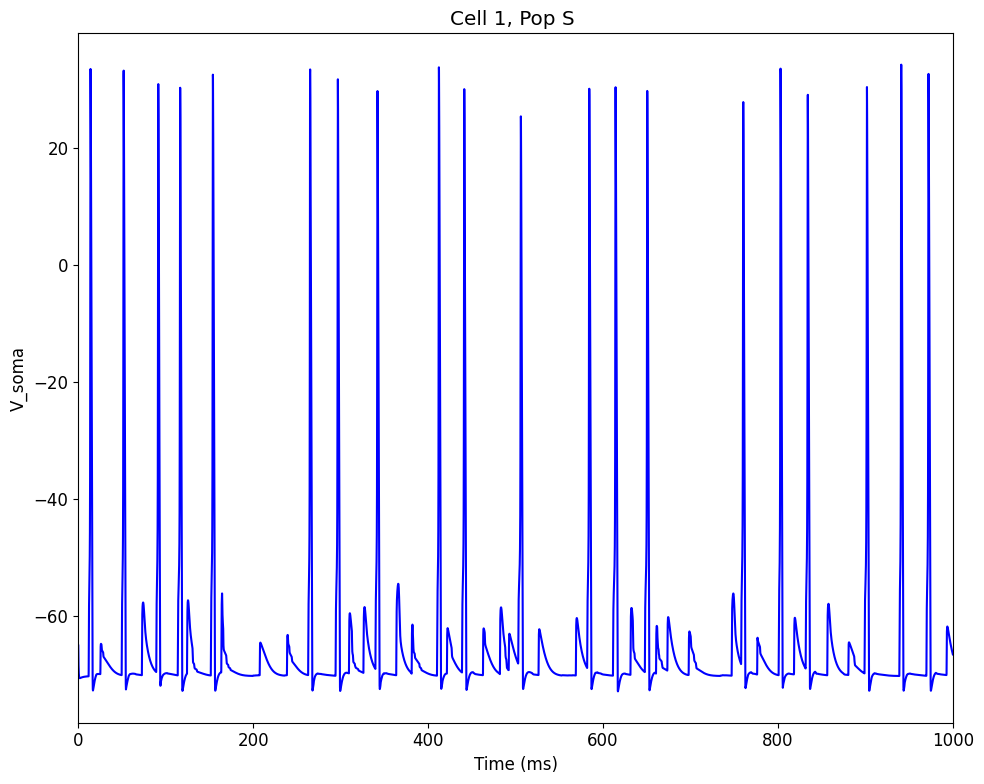

Plotting firing rate spectrogram ...


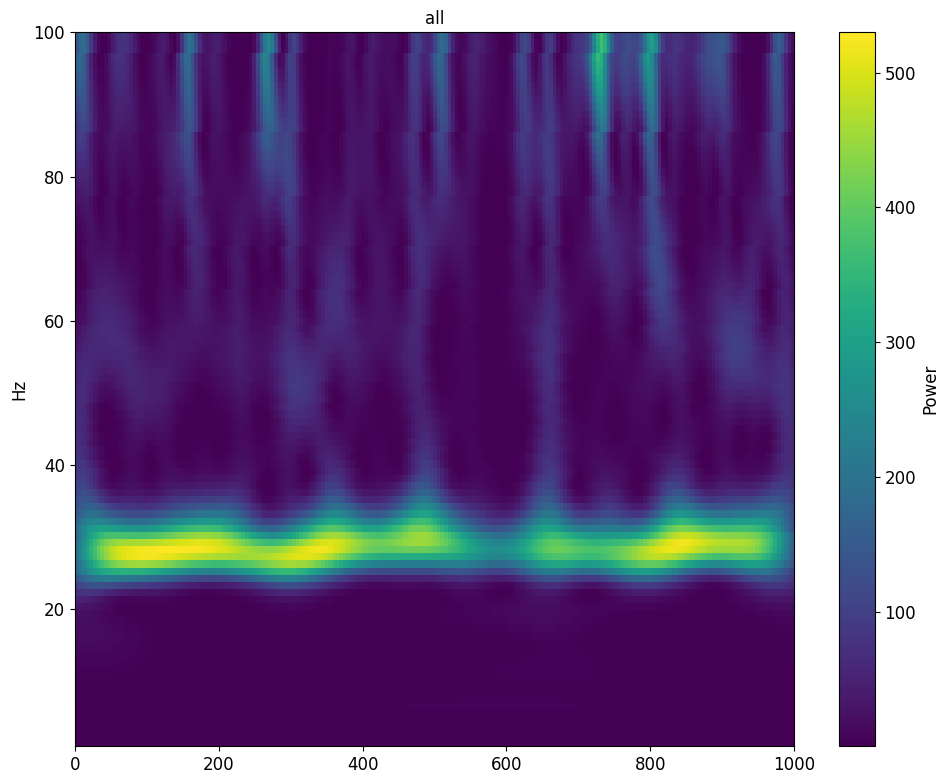

Plotting 2D representation of network cell locations and connections...


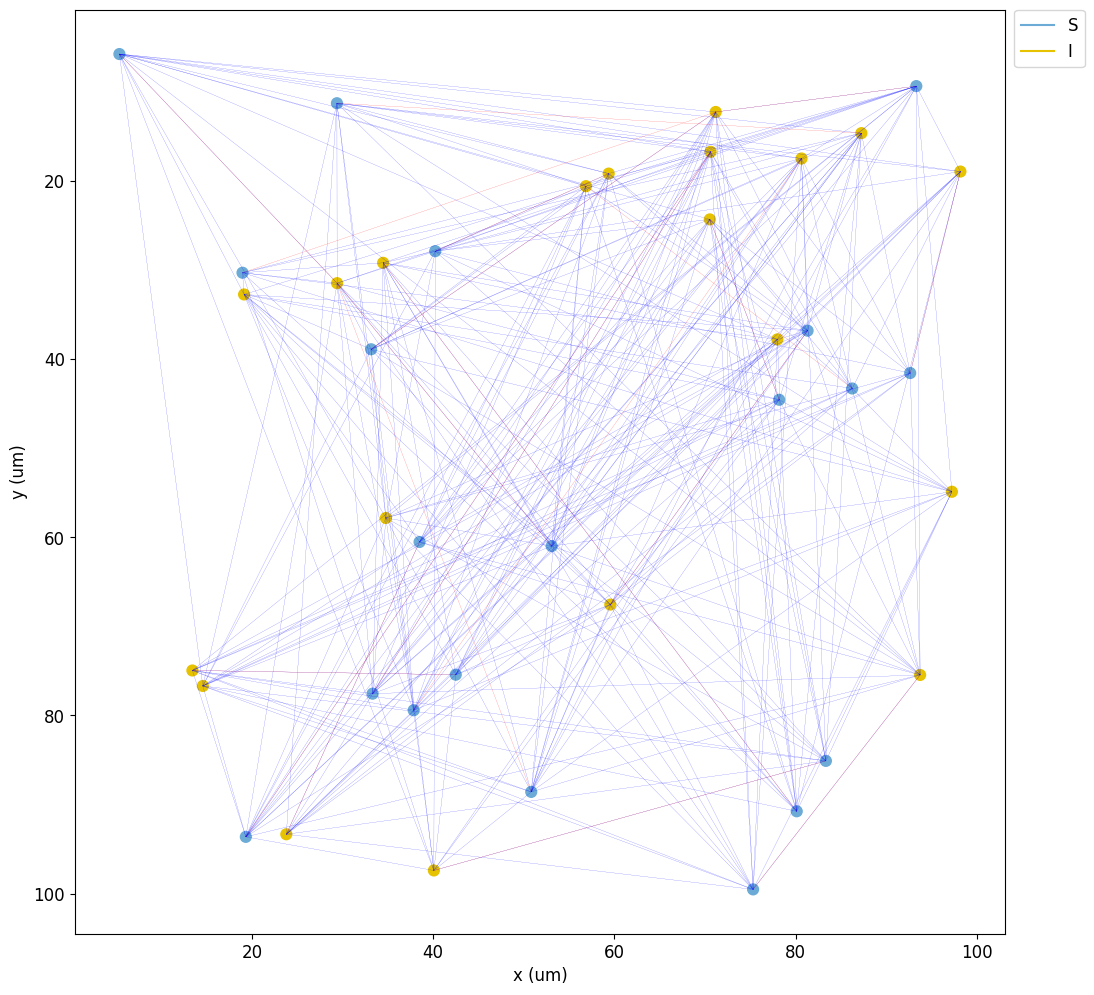

Preparing spike data...
Plotting spike histogram...
  Done; plotting time = 1.00 s

Total time = 1.54 s
Preparing spike data...
Plotting raster...


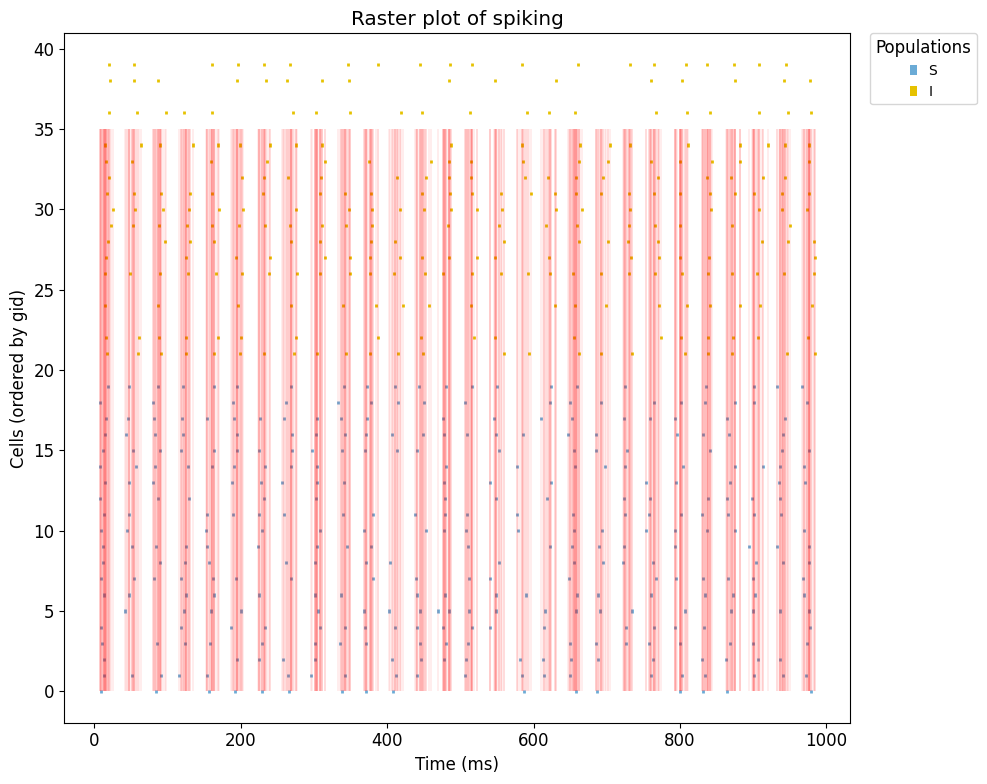

In [1]:
import matplotlib
%matplotlib inline
from netpyne import sim, specs

netParams = specs.NetParams()  

PYRcell = {'secs': {}}
PYRcell['secs']['soma'] = {'geom': {}, 'mechs': {}}
PYRcell['secs']['soma']['geom'] = {'diam': 18.8, 'L': 18.8, 'Ra': 123.0}                           
PYRcell['secs']['soma']['mechs']['hh'] = {'gnabar': 0.12, 'gkbar': 0.036, 'gl': 0.003, 'el': -70}  
netParams.cellParams['PYR'] = PYRcell


netParams.popParams['S'] = {'cellType': 'PYR', 'numCells': 20}
netParams.popParams['I'] = {'cellType': 'PYR', 'numCells': 20}

netParams.synMechParams['exc'] = {'mod': 'Exp2Syn', 'tau1': 0.1, 'tau2': 5.0, 'e': 0}  
netParams.synMechParams['inh'] = {'mod': 'Exp2Syn', 'tau1': 0.1, 'tau2': 5.0, 'e': -70}  


netParams.stimSourceParams['bkg'] = {'type': 'NetStim', 'rate': 50, 'noise': 0.5}
netParams.stimTargetParams['bkg->S'] = {
        'source': 'bkg', 
        'conds': {'pop': 'S'}, 
        'weight': 0.01, 
        'delay': 5, 
        'synMech': 'exc'}

netParams.connParams['S->I'] = { 
        'preConds': {'pop': 'S'},   
        'postConds': {'pop': 'I'},  
        'divergence': 1,
        #'probability': 0.5,         
        'weight': 0.01,             
        'delay': 5,                 
        'synMech': 'exc'} 

netParams.connParams['I->S'] = { 
        'preConds': {'pop': 'I'},   
        'postConds': {'pop': 'S'},  
        #'divergence': 1,
        'probability': 0.7,         
        'weight': 0.02,             
        'delay': 5,                 
        'synMech': 'inh'} 

#simu opt
simConfig = specs.SimConfig()

simConfig.duration = 1*1e3
simConfig.dt = 0.025
simConfig.verbose = False
simConfig.recordTraces = {'V_soma' : {'sec':'soma', 'loc' : 0.5, 'var' : 'v'}}
simConfig.recordStep = 0.1
simConfig.filename = 'try'
simConfig.savePickle = False
simConfig.saveJson = False

simConfig.analysis['plotRaster'] = {'syncLines': True, 'saveFig': True}
simConfig.analysis['plotTraces'] = {'include': [1], 'saveFig': True}
simConfig.analysis['plotRateSpectrogram'] = {'include': {'all'}}
simConfig.analysis['plot2Dnet'] = {'saveFig': True}                   # plot 2D cell positions and connections
simConfig.analysis['plotSpikeHist'] = {'include': {'S','I'}, 'saveFig': True}

sim.createSimulateAnalyze(netParams=netParams, simConfig=simConfig)

sim.analysis.plotRaster(syncLines= True)


In [ ]:
%matplotlib inline
from netpyne import sim, specs

netParams = specs.NetParams()  

PYRcell = {'secs': {}}
PYRcell['secs']['soma'] = {'geom': {}, 'mechs': {}}
PYRcell['secs']['soma']['geom'] = {'diam': 18.8, 'L': 18.8, 'Ra': 123.0}                           
PYRcell['secs']['soma']['mechs']['hh'] = {'gnabar': 0.12, 'gkbar': 0.036, 'gl': 0.003, 'el': -70}  
netParams.cellParams['PYR'] = PYRcell


netParams.popParams['S'] = {'cellType': 'PYR', 'numCells': 20}
netParams.popParams['I'] = {'cellType': 'PYR', 'numCells': 20}

netParams.synMechParams['exc'] = {'mod': 'Exp2Syn', 'tau1': 0.1, 'tau2': 5.0, 'e': 0}  
netParams.synMechParams['inh'] = {'mod': 'Exp2Syn', 'tau1': 0.1, 'tau2': 15.0, 'e': -70}  


netParams.stimSourceParams['bkg'] = {'type': 'NetStim', 'rate': 50, 'noise': 0.5}
netParams.stimTargetParams['bkg->S'] = {
        'source': 'bkg', 
        'conds': {'pop': 'S'}, 
        'weight': 0.01, 
        'delay': 5, 
        'synMech': 'exc'}

netParams.connParams['S->I'] = { 
        'preConds': {'pop': 'S'},   
        'postConds': {'pop': 'I'},  
        'divergence': 1,
        #'probability': 0.5,         
        'weight': 0.01,             
        'delay': 5,                 
        'synMech': 'exc'} 

netParams.connParams['I->S'] = { 
        'preConds': {'pop': 'I'},   
        'postConds': {'pop': 'S'},  
        #'divergence': 1,
        'probability': 0.7,         
        'weight': 0.02,             
        'delay': 5,                 
        'synMech': 'inh'} 

#simu opt
simConfig = specs.SimConfig()

simConfig.duration = 1*1e3
simConfig.dt = 0.025
simConfig.verbose = False
simConfig.recordTraces = {'V_soma' : {'sec':'soma', 'loc' : 0.5, 'var' : 'v'}}
simConfig.recordStep = 0.1
simConfig.filename = 'try'
simConfig.savePickle = False
simConfig.saveJson = False

simConfig.analysis['plotRaster'] = {'syncLines': True, 'saveFig': True}
simConfig.analysis['plotTraces'] = {'include': [1], 'saveFig': True}
simConfig.analysis['plotRateSpectrogram'] = {'include': {'all'}}
simConfig.analysis['plot2Dnet'] = {'saveFig': True}                   # plot 2D cell positions and connections
simConfig.analysis['plotSpikeHist'] = {'include': {'S','I'}, 'saveFig': True}

sim.createSimulateAnalyze(netParams=netParams, simConfig=simConfig)

sim.analysis.plotRaster(syncLines= True)





In [ ]:
%matplotlib inline
from netpyne import sim, specs

netParams = specs.NetParams()  

PYRcell = {'secs': {}}
PYRcell['secs']['soma'] = {'geom': {}, 'mechs': {}}
PYRcell['secs']['soma']['geom'] = {'diam': 18.8, 'L': 18.8, 'Ra': 123.0}                           
PYRcell['secs']['soma']['mechs']['hh'] = {'gnabar': 0.12, 'gkbar': 0.036, 'gl': 0.003, 'el': -70}  
netParams.cellParams['PYR'] = PYRcell


netParams.popParams['S'] = {'cellType': 'PYR', 'numCells': 20}
netParams.popParams['I'] = {'cellType': 'PYR', 'numCells': 20}

netParams.synMechParams['exc'] = {'mod': 'Exp2Syn', 'tau1': 0.1, 'tau2': 5.0, 'e': 0}  
netParams.synMechParams['inh'] = {'mod': 'Exp2Syn', 'tau1': 0.1, 'tau2': 5.0, 'e': -70}  


netParams.stimSourceParams['bkg'] = {'type': 'NetStim', 'rate': 50, 'noise': 0.5}
netParams.stimTargetParams['bkg->S'] = {
        'source': 'bkg', 
        'conds': {'pop': 'S'}, 
        'weight': 0.01, 
        'delay': 5, 
        'synMech': 'exc'}

netParams.connParams['S->I'] = { 
        'preConds': {'pop': 'S'},   
        'postConds': {'pop': 'I'},  
        'divergence': 10,
        #'probability': 0.5,         
        'weight': 0.01,             
        'delay': 5,                 
        'synMech': 'exc'} 

netParams.connParams['I->S'] = { 
        'preConds': {'pop': 'I'},   
        'postConds': {'pop': 'S'},  
        #'divergence': 1,
        'probability': 0.7,         
        'weight': 0.02,             
        'delay': 5,                 
        'synMech': 'inh'} 

#simu opt
simConfig = specs.SimConfig()

simConfig.duration = 1*1e3
simConfig.dt = 0.025
simConfig.verbose = False
simConfig.recordTraces = {'V_soma' : {'sec':'soma', 'loc' : 0.5, 'var' : 'v'}}
simConfig.recordStep = 0.1
simConfig.filename = 'try'
simConfig.savePickle = False
simConfig.saveJson = False

simConfig.analysis['plotRaster'] = {'syncLines': True, 'saveFig': True}
simConfig.analysis['plotTraces'] = {'include': [1], 'saveFig': True}
simConfig.analysis['plotRateSpectrogram'] = {'include': {'all'}}
simConfig.analysis['plot2Dnet'] = {'saveFig': True}                   # plot 2D cell positions and connections
simConfig.analysis['plotSpikeHist'] = {'include': {'S','I'}, 'saveFig': True}

sim.createSimulateAnalyze(netParams=netParams, simConfig=simConfig)

sim.analysis.plotRaster(syncLines= True)






Start time:  2025-04-21 16:32:47.929188




Creating network of 6 cell populations on 1 hosts...: 100%|##########|


  Number of cells on node 0: 300 
  Done; cell creation time = 0.04 s.
Making connections...


  E->all: 100%|##########| Creating synaptic connections for 300/300 postsynaptic cells on node 0 (probabilistic connectivity)
  I->E: 100%|##########| Creating synaptic connections for 150/150 postsynaptic cells on node 0 (probabilistic connectivity)


  Number of connections on node 0: 6796 
  Done; cell connection time = 0.66 s.
Adding stims...
  Number of stims on node 0: 300 
  Done; cell stims creation time = 0.02 s.
Recording 3 traces of 1 types on node 0

Running simulation using NEURON for 1000.0 ms...
  Done; run time = 6.85 s; real-time ratio: 0.15.

Gathering data...
  Done; gather time = 0.11 s.

Analyzing...
  Cells: 300
  Connections: 7096 (23.65 per cell)
  Spikes: 4902 (16.34 Hz)
  Simulated time: 1.0 s; 1 workers
  Run time: 6.85 s
Preparing spike data...
Plotting raster...
Plotting recorded cell traces ... cell


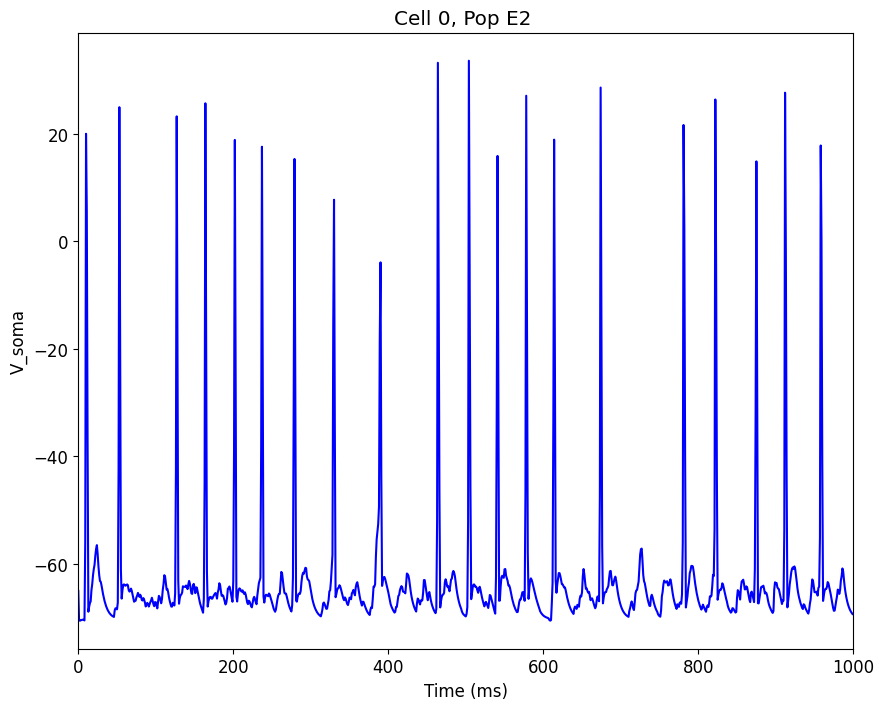

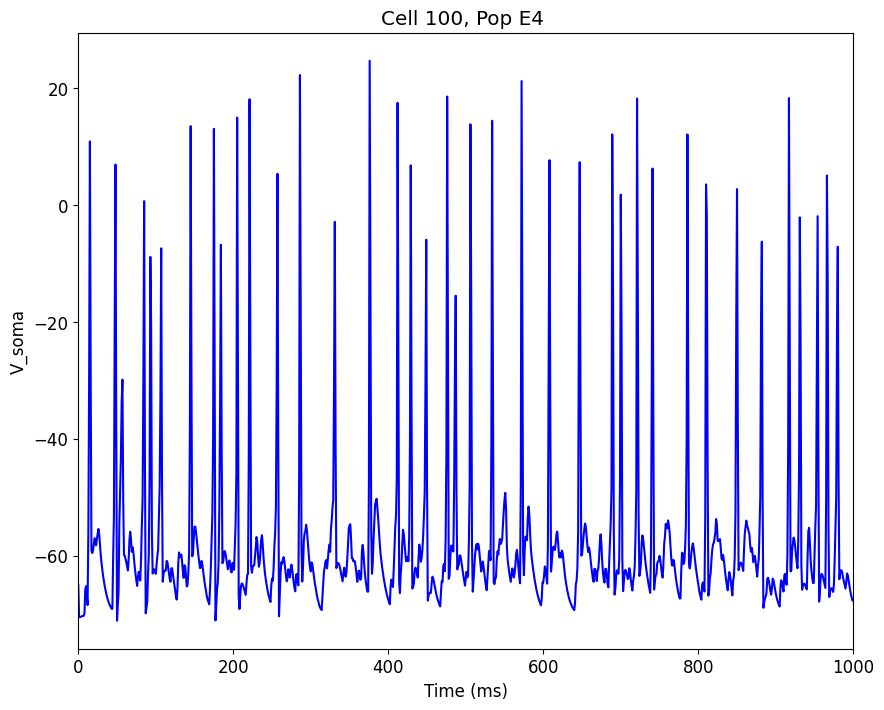

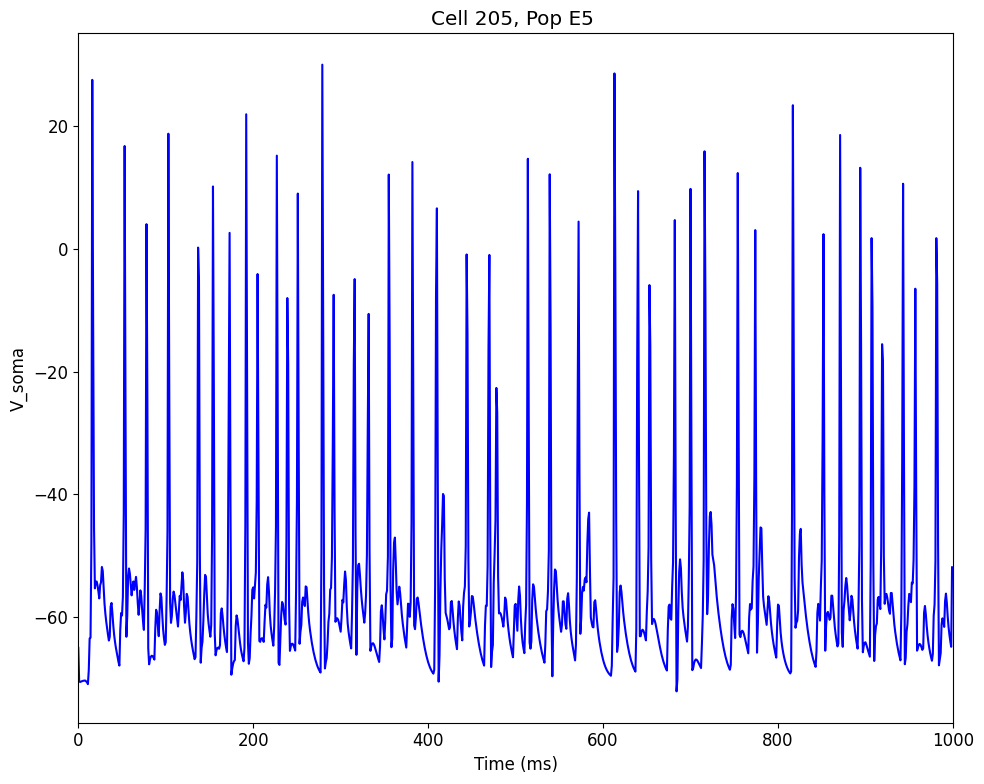

Plotting 2D representation of network cell locations and connections...


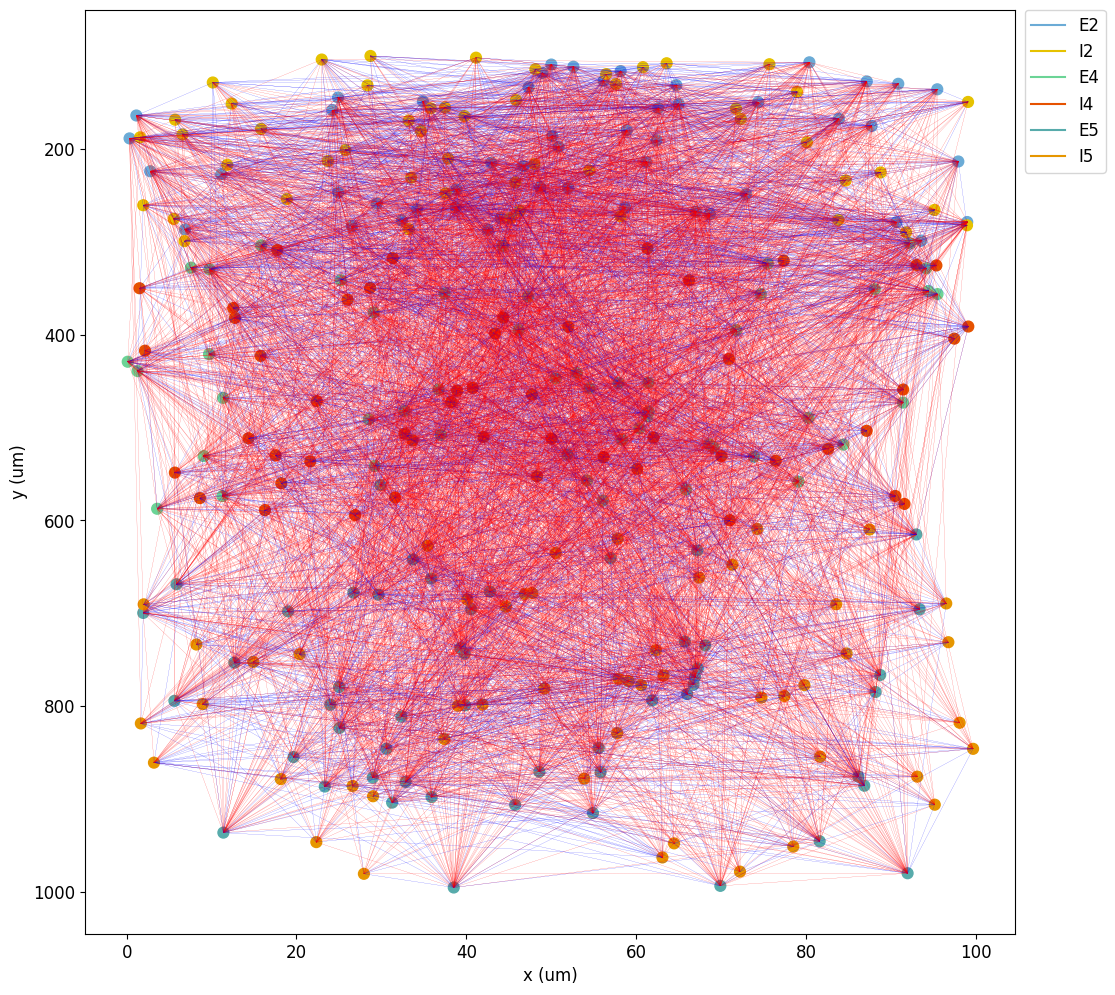

Plotting connectivity matrix...


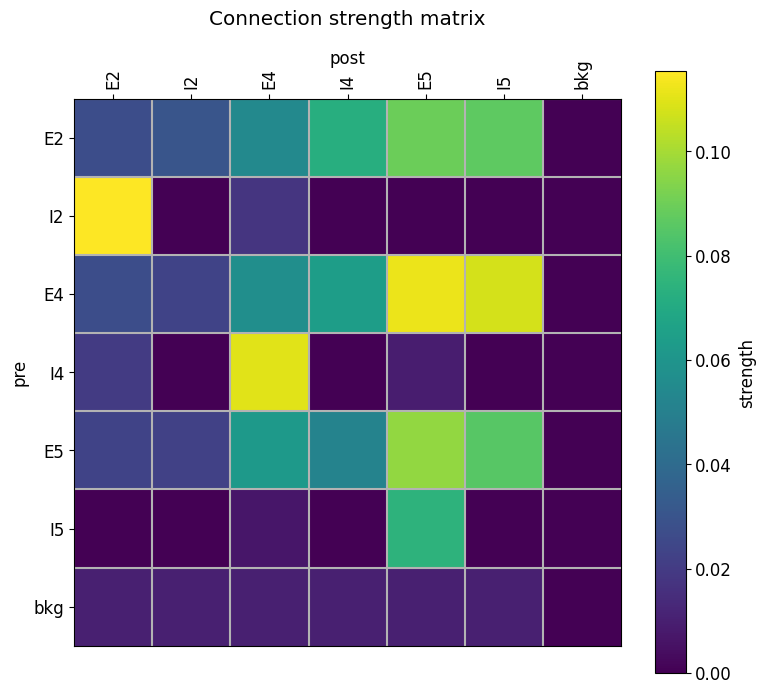

Plotting 2D representation of network cell locations and connections...


MovieWriter ffmpeg unavailable; using Pillow instead.


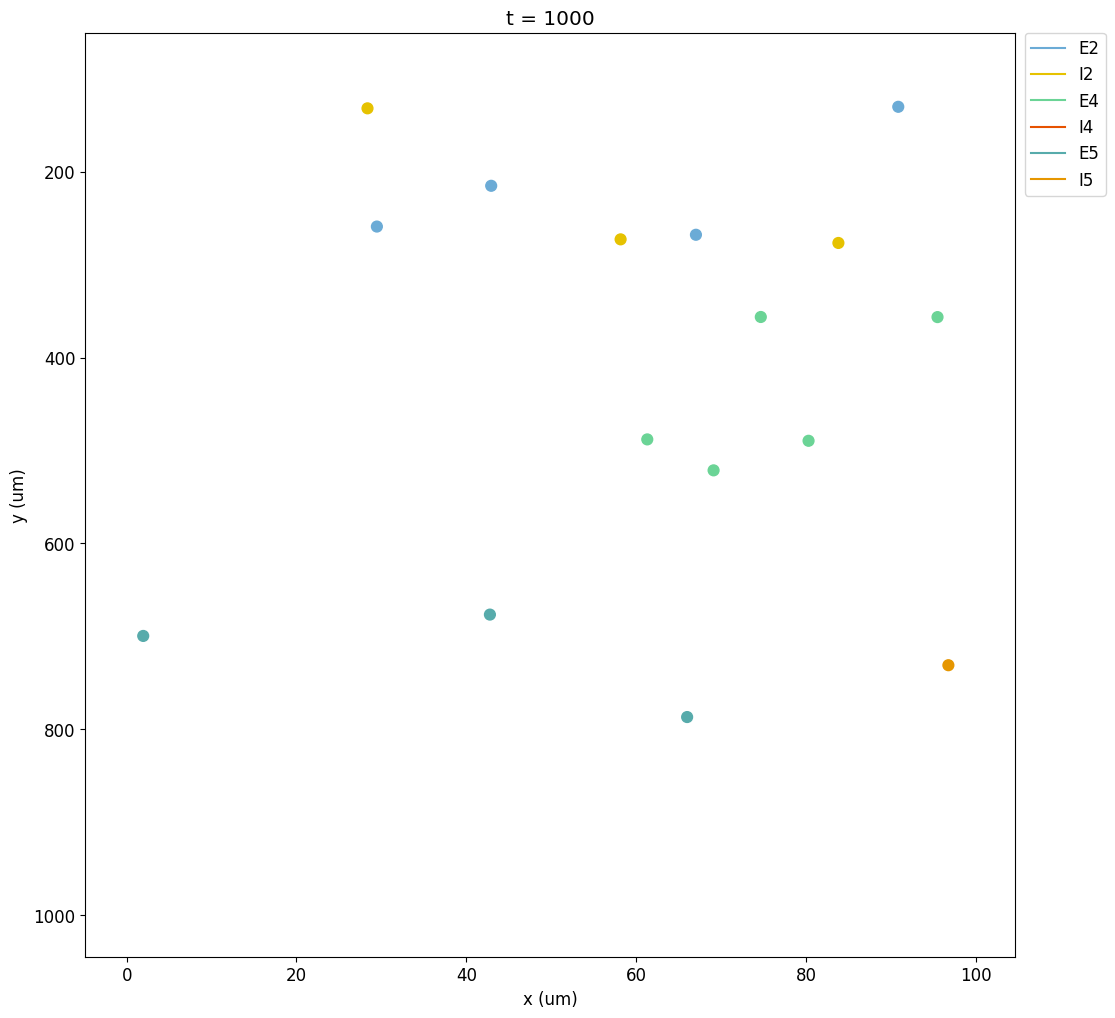

  Done; plotting time = 21.65 s

Total time = 29.35 s


In [ ]:
from netpyne import specs, sim

# Network param
netParams = specs.NetParams()  

netParams.sizeX = 100              
netParams.sizeY = 1000             
netParams.sizeZ = 100              
netParams.propVelocity = 100.0     
netParams.probLengthConst = 150.0  

## Cell
secs = {} #
secs['soma'] = {'geom': {}, 'mechs': {}}                                                
secs['soma']['geom'] = {'diam': 15, 'L': 14, 'Ra': 120.0}                               
secs['soma']['mechs']['hh'] = {'gnabar': 0.13, 'gkbar': 0.036, 'gl': 0.003, 'el': -70}  
netParams.cellParams['E'] = {'secs': secs}                                              

secs = {} 
secs['soma'] = {'geom': {}, 'mechs': {}}                                                
secs['soma']['geom'] = {'diam': 10.0, 'L': 9.0, 'Ra': 110.0}                            
secs['soma']['mechs']['hh'] = {'gnabar': 0.11, 'gkbar': 0.036, 'gl': 0.003, 'el': -70}  
netParams.cellParams['I'] = {'secs': secs}                                              

## Pop
netParams.popParams['E2'] = {'cellType': 'E', 'numCells': 50, 'yRange': [100,300]}
netParams.popParams['I2'] = {'cellType': 'I', 'numCells': 50, 'yRange': [100,300]}
netParams.popParams['E4'] = {'cellType': 'E', 'numCells': 50, 'yRange': [300,600]}
netParams.popParams['I4'] = {'cellType': 'I', 'numCells': 50, 'yRange': [300,600]}
netParams.popParams['E5'] = {'cellType': 'E', 'numCells': 50, 'ynormRange': [0.6,1.0]}
netParams.popParams['I5'] = {'cellType': 'I', 'numCells': 50, 'ynormRange': [0.6,1.0]}


## Synaptic con
netParams.synMechParams['exc'] = {'mod': 'Exp2Syn', 'tau1': 0.8, 'tau2': 5.3, 'e': 0}  # NMDA 
netParams.synMechParams['inh'] = {'mod': 'Exp2Syn', 'tau1': 0.6, 'tau2': 8.5, 'e': -75}  # GABA 


# Stimulation
netParams.stimSourceParams['bkg'] = {'type': 'NetStim', 'rate': 20, 'noise': 0.3}
netParams.stimTargetParams['bkg->all'] = {
    'source': 'bkg',
    'conds': {'cellType': ['E','I']},
    'weight': 0.01,
    'delay': 'max(1, normal(5,2))',
    'synMech': 'exc'}


## Cell connectivity
netParams.connParams['E->all'] = {
    'preConds': {'cellType': 'E'}, 'postConds': {'y': [100,1000]},  
    'probability': 0.1 ,                  
    'weight': '0.005*post_ynorm',         
    'delay': 'dist_3D/propVelocity',      
    'synMech': 'exc'}                     

netParams.connParams['I->E'] = {
    'preConds': {'cellType': 'I'}, 'postConds': {'pop': ['E2','E4','E5']},       
    'probability': '0.4*exp(-dist_3D/probLengthConst)',   
    'weight': 0.001,                                      
    'delay': 'dist_3D/propVelocity',                      
    'synMech': 'inh'}                                     


# Simulation options
simConfig = specs.SimConfig()        
simConfig.duration = 1*1e3           # Duration ms
simConfig.dt = 0.025                 
simConfig.verbose = False            
simConfig.recordTraces = {'V_soma':{'sec':'soma','loc':0.5,'var':'v'}}  
simConfig.recordStep = 1             # Step size in ms
simConfig.filename = 'Net_NMDA_GABA'          
simConfig.savePickle = False         
simConfig.saveMat = False            


simConfig.analysis['plotRaster'] = {'orderBy': 'y', 'orderInverse': True, 'saveFig': True}         
simConfig.analysis['plotTraces'] = {'include': [('E2',0), ('E4', 0), ('E5', 5)], 'saveFig': True}  
simConfig.analysis['plot2Dnet'] = {'saveFig': True}                                                
simConfig.analysis['plotConn'] = {'saveFig': True}                                                 
simConfig.analysis['plot2Dfiring'] = {'saveFig': True, 'showFig': True}

sim.createSimulateAnalyze(netParams = netParams, simConfig = simConfig)



In [ ]:
!git clone https://github.com/suny-downstate-medical-center/netpyne-course-2021.git
!nrnivmodl netpyne-course-2021

Cloning into 'netpyne-course-2021'...
remote: Enumerating objects: 100, done.
remote: Counting objects: 100% (100/100), done.
remote: Compressing objects: 100% (79/79), done.
remote: Total 100 (delta 30), reused 77 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (100/100), 116.59 KiB | 1.55 MiB/s, done.
Resolving deltas: 100% (30/30), done.


In [ ]:
!nrnivmodl netpyne-course-2021


Start time:  2025-04-21 18:51:41.850066




Creating network of 5 cell populations on 1 hosts...: 100%|##########|


  Number of cells on node 0: 500 
  Done; cell creation time = 0.03 s.
Making connections...


  NetStim->PYR1: 100%|##########| Creating synaptic connections for 100/100 postsynaptic cells on node 0 (convergent connectivity)
  VecStim->PYR1: 100%|##########| Creating synaptic connections for 100/100 postsynaptic cells on node 0 (probabilistic connectivity)
  PYR1->IntFire2: 100%|##########| Creating synaptic connections for 100/100 postsynaptic cells on node 0 (probabilistic connectivity)
  IntFire2->IntFire4: 100%|##########| Creating synaptic connections for 100/100 postsynaptic cells on node 0 (probabilistic connectivity)


  Number of connections on node 0: 7227 
  Done; cell connection time = 0.54 s.
  Number of stims on node 0: 0 
  Done; cell stims creation time = 0.00 s.
Recording 1 traces of 1 types on node 0

Running simulation using NEURON for 1000.0 ms...
  Done; run time = 1.38 s; real-time ratio: 0.73.

Gathering data...
  Done; gather time = 0.25 s.

Analyzing...
  Cells: 500
  Connections: 7227 (14.45 per cell)
  Spikes: 6543 (13.09 Hz)
  Simulated time: 1.0 s; 1 workers
  Run time: 1.38 s
Preparing spike data...
Plotting raster...
Plotting recorded cell traces ... cell


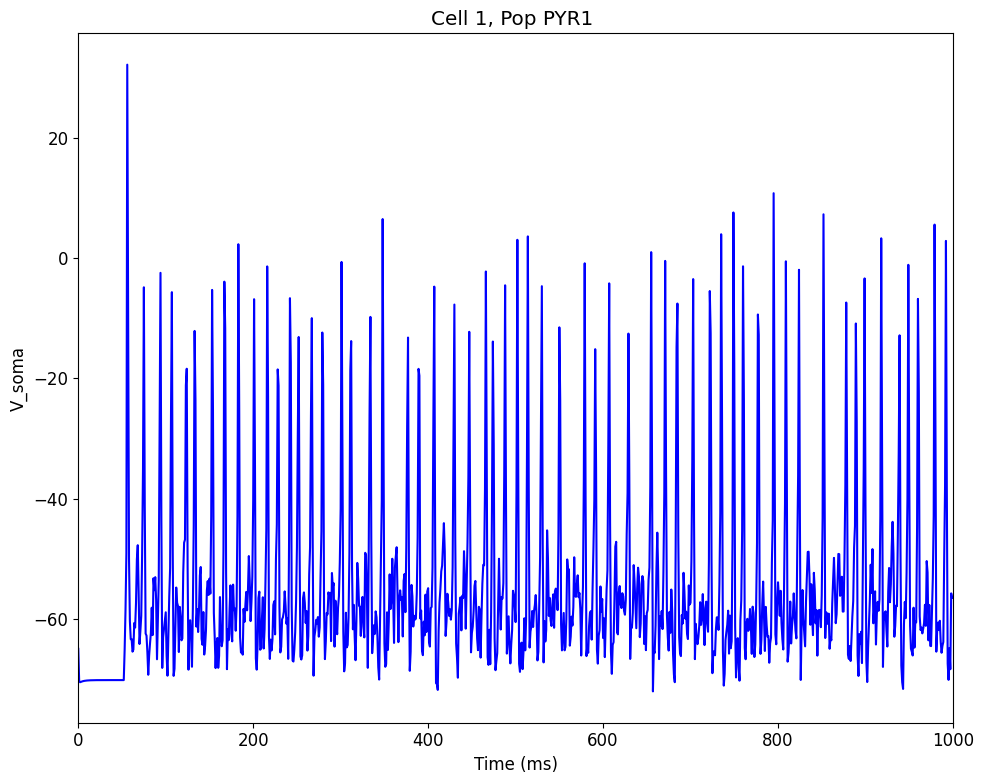

  Done; plotting time = 0.42 s

Total time = 2.63 s
Preparing spike data...
Plotting raster...


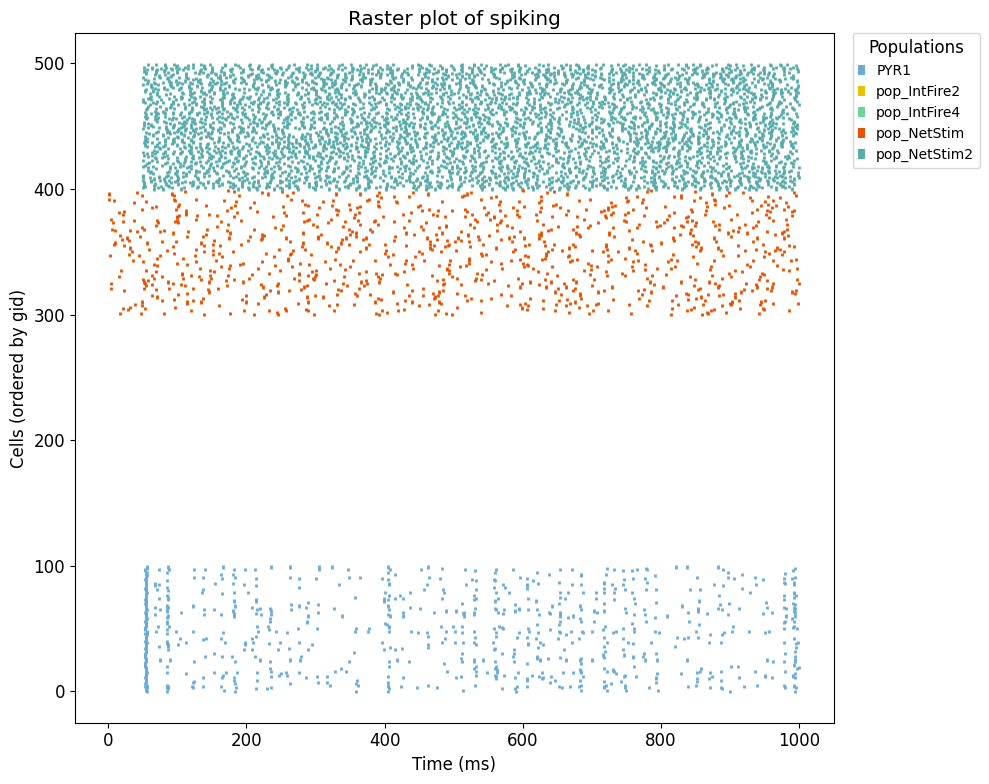

In [8]:
from netpyne import specs, sim
from netpyne.specs import Dict

netParams = specs.NetParams()
simConfig = specs.SimConfig()

cellParams=Dict()
cellParams.secs.soma.geom = {'diam': 18.8, 'L': 18.8, 'Ra': 123.0}
cellParams.secs.soma.mechs.hh = {'gnabar': 0.12, 'gkbar': 0.036, 'gl': 0.003, 'el': -70}  
netParams.cellParams['PYR'] = cellParams

netParams.cellParams['artif_InFire2'] = {'cellModel': 'IntFire2', 'ib':0}
netParams.cellParams['artif_InFire4'] = {'cellModel': 'IntFire4','taue': 1.0}
netParams.cellParams['artif_NetStim'] = {'cellModel': 'NetStim'} #poisson type of spikes
# netParams.cellParams['artif_VecStim'] = {
#     'cellModel': 'VecStim'} #pop of vecstims with 2 pulses


netParams.popParams['PYR1'] = {
    'cellType': 'PYR',
    'numCells': 100}
netParams.popParams['pop_IntFire2'] = {'cellModel': 'IntFire2', 'taum': 100, 'noise': 0.5, 'numCells': 100}
netParams.popParams['pop_IntFire4'] = {'cellModel': 'IntFire4', 'numCells':100}
    # 'cellType': 'artif_IntFire4',
    # 'numCells': 100}
netParams.popParams['pop_NetStim'] = { #for correlated input connection divergence pop 2 pop
    'cellType': 'artif_NetStim',
    'numCells': 100,
    'rate': 10,
    'noise': 0.8,
    'start': 1,
    'seed': 2} 
netParams.popParams['pop_NetStim2'] = { #for correlated input connection divergence pop 2 pop
    'cellType': 'artif_NetStim',
    'numCells': 100,
    'rate': 50,
    'noise': 0.5,
    'start': 50} 
#spkTimes = range(0,1000,20) + [138,155,270] #ms, can be 2dim
#spkTimes = [[138,155,270],[2,4],...]] each [] is for one cell
# netParams.popParams['pop_VecStim'] = { #pop of Vecstim with 2 pulses
#     'cellType': 'artif_VecStim',
#     'numCells': 100,
#     #'spkTimes': spkTimes, #predefines spiketimes cobined with pulses
#     'rate': 5,
#     'noise': 0.5,
#     'start': 50,
#     'pulses': [{'start': 200, 'end': 300, 'rate': 60, 'noise': 0.2},
#                {'start': 500, 'end': 800, 'rate': 30, 'noise': 0.5}]} 

netParams.synMechParams['AMPA'] = {'mod': 'Exp2Syn', 'tau1': 0.1, 'tau2': 1.0, 'e': 0}  
#netParams.synMechParams['GABA'] = {'mod': 'Exp2Syn', 'tau1': 0.6, 'tau2': 8.5, 'e': -75}  

netParams.connParams['NetStim->PYR1'] = {
    'preConds': {'pop': 'pop_NetStim'},
    'postConds': {'pop': 'PYR1'},
    'convergence': 3, #each pyr receive inputs from 3 netstim randomly selected
    'weight': 0.002,
    'synMech': 'AMPA',
    'delay': 'uniform(1,5)'}
netParams.connParams['VecStim->PYR1'] = {
    'preConds': {'pop': 'pop_NetStim2'}, #need to change to VecStim
    'postConds': {'pop': 'PYR1'},
    'probability': 0.4,
    'weight': 0.005,
    'synMech': 'AMPA',
    'delay': 'uniform(1,5)'}
netParams.connParams['PYR1->IntFire2'] = {
    'preConds': {'pop': 'PYR1'},
    'postConds': {'pop': 'pop_IntFire2'},
    'probability': 0.2,
    'weight': 0.01,
    'delay': 'uniform(1,5)'}
netParams.connParams['IntFire2->IntFire4'] = {
    'preConds': {'pop': 'pop_IntFire2'},
    'postConds': {'pop': 'pop_IntFire4'},
    'probability': 0.1,
    'weight': 0.2,
    'delay': 'uniform(1,5)'}

# Simulation param
simConfig = specs.SimConfig()        
simConfig.duration = 1*1e3       #ms    
simConfig.dt = 0.1
simConfig.createNEURONObj = 1
simConfig.createPyStruct = 1                 
simConfig.verbose = False   

simConfig.recordTraces = {'V_soma':{'sec':'soma','loc':0.5,'var':'v'}}  
simConfig.recordStep = 1             # Step size in ms
simConfig.filename = 'Net_AMPA'          
# simConfig.savePickle = False         
# simConfig.saveMat = False            


simConfig.analysis['plotRaster'] = {'orderInverse': True, 'saveFig': True}         
simConfig.analysis['plotTraces'] = {'include': [1], 'saveFig': True}  
# simConfig.analysis['plot2Dnet'] = {'saveFig': True}                                                
# simConfig.analysis['plotConn'] = {'saveFig': True}                                                 
# simConfig.analysis['plot2Dfiring'] = {'saveFig': True, 'showFig': True}

sim.createSimulateAnalyze() #netParams = netParams, simConfig = simConfig

sim.analysis.plotRaster()



Start time:  2025-04-21 18:57:53.086409




Creating network of 2 cell populations on 1 hosts...: 100%|##########|

  Number of cells on node 0: 40 
  Done; cell creation time = 0.02 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
Adding stims...
  Number of stims on node 0: 48 
  Done; cell stims creation time = 0.01 s.
Recording 2 traces of 1 types on node 0

Running simulation using NEURON for 1000.0 ms...



exp(830.94) out of range, returning exp(700)
exp(831.44) out of range, returning exp(700)
exp(829.44) out of range, returning exp(700)
exp(1211.76) out of range, returning exp(700)
No more errno warnings during this execution


  Done; run time = 1.02 s; real-time ratio: 0.98.

Gathering data...
  Done; gather time = 0.00 s.

Analyzing...
  Cells: 40
  Connections: 16 (0.40 per cell)
  Spikes: 135 (3.38 Hz)
  Simulated time: 1.0 s; 1 workers
  Run time: 1.02 s
Preparing spike data...
Plotting raster...
Plotting recorded cell traces ... cell


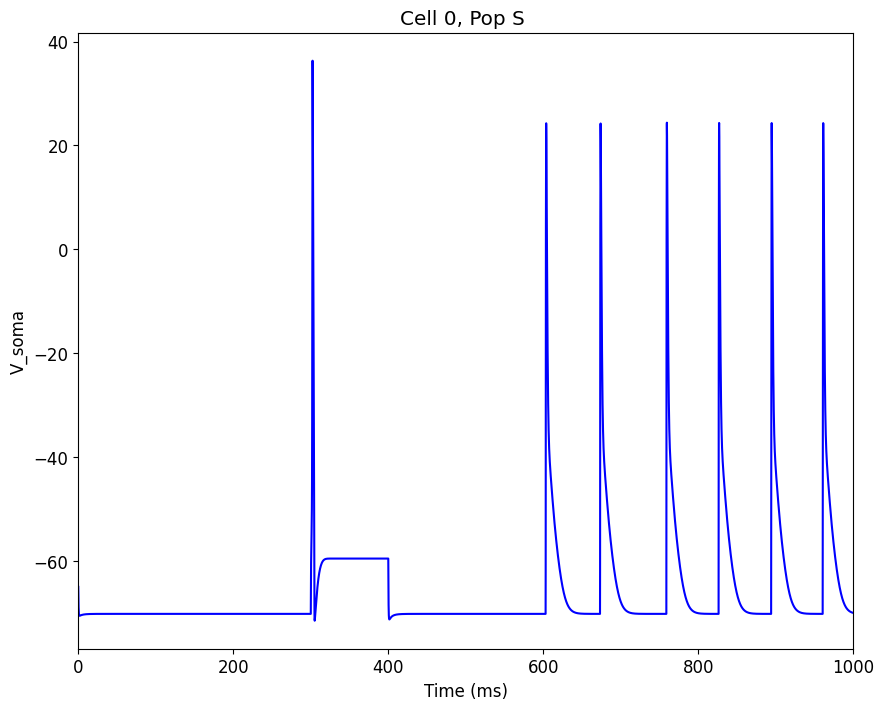

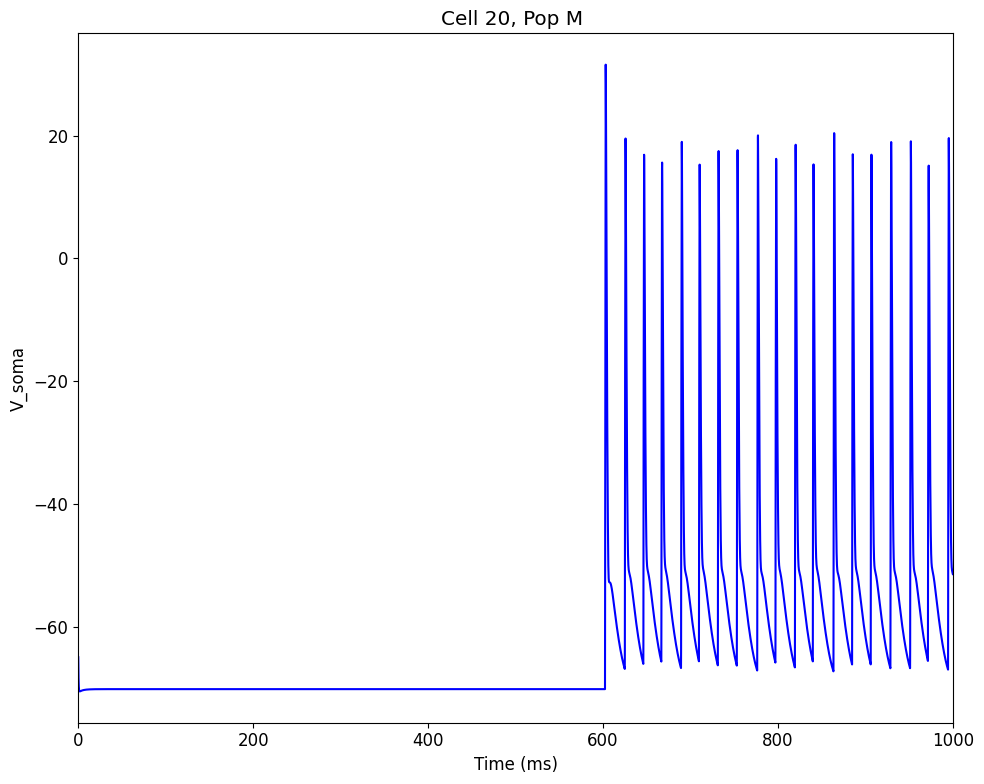

  Done; plotting time = 0.39 s

Total time = 1.44 s
Preparing spike data...
Plotting raster...


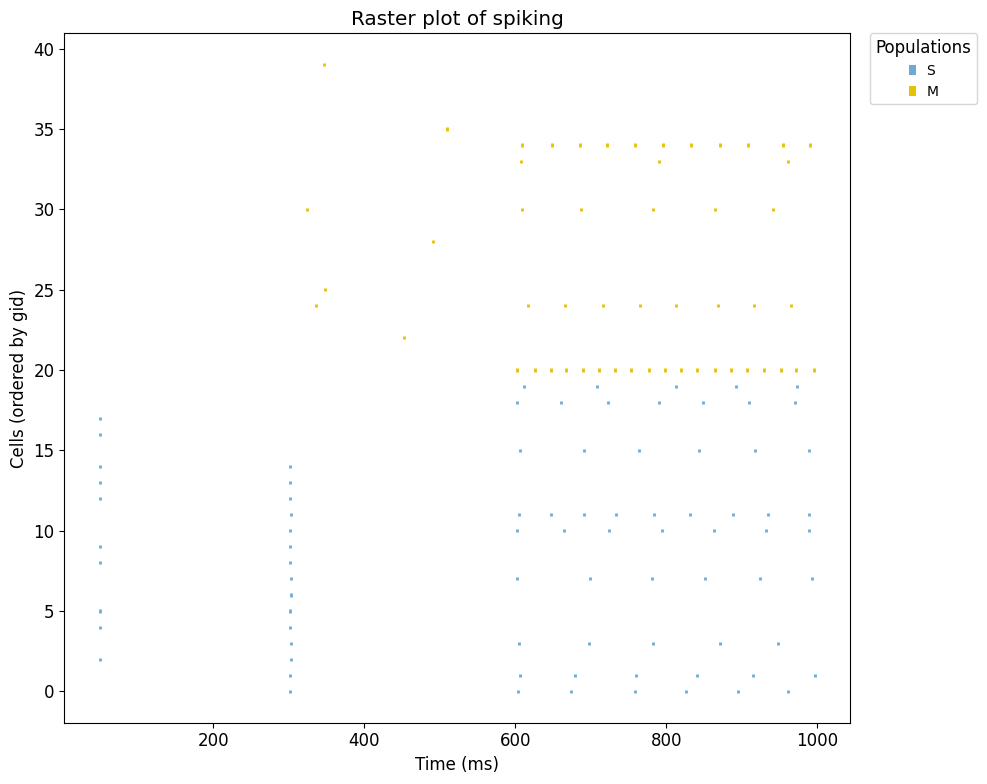

In [ ]:
from netpyne import specs, sim
from netpyne.specs import Dict

netParams = specs.NetParams()
simConfig = specs.SimConfig()

cellParams=Dict()
cellParams.secs.soma.geom = {'diam': 18.8, 'L': 18.8, 'Ra': 123.0}
cellParams.secs.soma.mechs.hh = {'gnabar': 0.12, 'gkbar': 0.036, 'gl': 0.003, 'el': -70}  
netParams.cellParams['PYR'] = cellParams                                              # add dict to list of cell params

## Population parameters
netParams.popParams['S'] = {'cellType': 'PYR', 'numCells': 20}
netParams.popParams['M'] = {'cellType': 'PYR', 'numCells': 20}

## Synaptic mechanism parameters
netParams.synMechParams['exc'] = {
    'mod': 'Exp2Syn',
    'tau1': '0.1 + 0.01*post_ynorm',
    'tau2': 'abs(normal(5.0, 0.5))',
    'e': 0
}  # excitatory synaptic mechanism

## Stimulation parameters one copy of each copy to the stimulus sources per each target cell
netParams.stimSourceParams['Input_1'] = {'type': 'IClamp', 'del': 300, 'dur': 100, 'amp': 'uniform(0.4,0.5)'}
netParams.stimSourceParams['Input_2'] = {'type': 'VClamp', 'dur': [0,50,200], 'amp': [-60,-30,40], 'gain': 1e5, 'rstim': 1, 'tau1': 0.1, 'tau2': 0}
netParams.stimSourceParams['Input_3'] = {'type': 'AlphaSynapse', 'onset': 'uniform(300,600)', 'tau': 5, 'gmax': 'post_ynorm', 'e': 0}
netParams.stimSourceParams['Input_4'] = {'type': 'NetStim', 'interval': 'uniform(20,100)', 'start': 600, 'noise': 0.1}

netParams.stimTargetParams['Input_1->S'] = {'source': 'Input_1', 'sec':'soma', 'loc': 0.8, 'conds': {'pop':'S', 'cellList': list(range(15))}}
netParams.stimTargetParams['Input_2->S'] = {'source': 'Input_2', 'sec':'soma', 'loc': 0.5, 'conds': {'pop':'S', 'ynorm': [0,0.5]}}
netParams.stimTargetParams['Input_3->M1'] = {'source': 'Input_3', 'sec':'soma', 'loc': 0.2, 'conds': {'pop':'M', 'cellList': [2,4,5,8,10,15,19]}}
netParams.stimTargetParams['Input_4->PYR'] = {'source': 'Input_4', 'sec':'soma', 'loc': 0.5, 'weight': '0.1+normal(0.2,0.05)','delay': 1,
                                            'conds': {'cellType':'PYR', 'ynorm': [0.6,1.0]}}


# Simulation options
simConfig = specs.SimConfig()       # object of class SimConfig to store simulation configuration

simConfig.duration = 1*1e3          # Duration of the simulation, in ms
simConfig.dt = 0.025                # Internal integration timestep to use
simConfig.verbose = False           # Show detailed messages
simConfig.recordTraces = {'V_soma':{'sec':'soma','loc':0.5,'var':'v'}}  # Dict with traces to record
simConfig.recordStep = 0.1          # Step size in ms to save data (eg. V traces, LFP, etc)
simConfig.filename = 'clamp_try'         # Set file output name
simConfig.savePickle = False        # Save params, network and sim output to pickle file

simConfig.analysis['plotRaster'] = {'saveFig': True}                                 # Plot a raster
simConfig.analysis['plotTraces'] = {'include': [('S',0), ('M',0)], 'saveFig': True}  # Plot recorded traces for this list of cells


# Create network and run simulation
sim.createSimulateAnalyze(netParams = netParams, simConfig = simConfig)

sim.analysis.plotRaster()
